Dataset:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Dataset Shape: (999, 9)

--- Simple Linear Regression ---
Intercept: 0.7577814114181443
Coefficient: 0.011612479296459727
R2 Score: -0.007128546996041152
RMSE: 1.4922251972120602

--- Multiple Linear Regression ---
Intercept: 0.807095787223069
Coefficients: [0.65367401 0.528

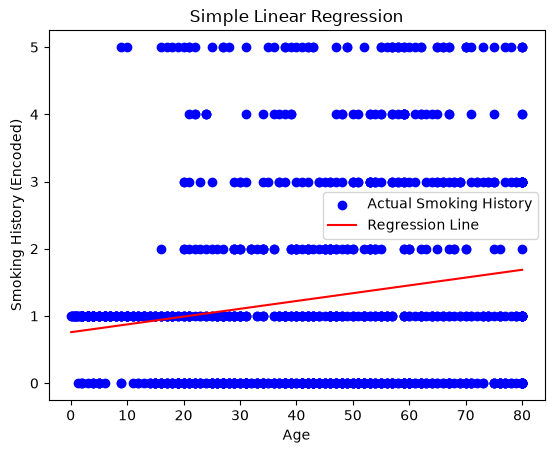

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

df = pd.read_csv(r"C:\Users\harsh\OneDrive\Desktop\NIE\DAV\diabetes_prediction_dataset.csv")

print("Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)


df["smoking_history"] = df["smoking_history"].map({
    "never": 0,
    "No Info": 1,
    "current": 2,
    "former": 3,
    "ever": 4,
    "not current": 5
})

df = df.dropna(subset=["smoking_history"])

X_simple = df[["age"]]
X_multiple = df[["heart_disease", "hypertension", "age"]]
y = df["smoking_history"]

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)


simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))


multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, multiple_predictions)))


new_sample_simple = pd.DataFrame({"age": [30]})

new_sample_multiple = pd.DataFrame({
    "heart_disease": [0],
    "hypertension": [0],
    "age": [30]
})

print(
    "\nPredicted smoking_history using Simple Regression:",
    simple_model.predict(new_sample_simple)[0]
)

print(
    "Predicted smoking_history using Multiple Regression:",
    multiple_model.predict(new_sample_multiple)[0]
)


plt.scatter(
    df["age"],
    df["smoking_history"],
    color="blue",
    label="Actual Smoking History"
)

plot_data = df[["age"]].sort_values(by="age")

plt.plot(
    plot_data["age"],
    simple_model.predict(plot_data),
    color="red",
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Smoking History (Encoded)")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()
